# Лабораторная работа 6
## Самовнимание, перестановки входов и производные softmax

Подсчёт параметров, доказательство эквивариантности и расчёт всех 25 производных softmax. Формулы сопровождаются вычислениями на NumPy.

Входные векторы располагаются **в столбцах**: $X\in\mathbb R^{D\times N}$, что соответствует записи $Sa(XP)=Sa(X)P$.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

LAB_DIR = Path.cwd().resolve()
if not (LAB_DIR / 'attention.py').is_file():
    LAB_DIR = LAB_DIR / 'Lab6'
if not (LAB_DIR / 'attention.py').is_file():
    raise FileNotFoundError('Рабочим каталогом должен быть корень проекта или Lab6')
sys.path.insert(0, str(LAB_DIR))
from attention import (parameter_counts, self_attention, initialize, permutation_matrix,
                       stable_softmax, softmax_jacobian)
from experiments import run_experiments, LOGITS, RTOL, ATOL

FIG_DIR = LAB_DIR / 'figures'
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 10)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda value: f'{value:.4e}')

def show_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, bbox_inches='tight')
    plt.show()
    plt.close(fig)

tables = run_experiments(LAB_DIR)

Число проверок перестановок: 120
Максимальное расхождение выходов: 4.4409e-16
J33: 5.6377e-42


### 1. Задача 1. Число параметров

Каждая из трёх проекций строит $D$-мерные векторы:

$$V=W_VX+b_V\mathbf1_N^T,\qquad K=W_KX+b_K\mathbf1_N^T,\qquad
Q=W_QX+b_Q\mathbf1_N^T.$$

У каждой проекции $D^2$ весов и $D$ смещений. Эти параметры общие для всех
$N$ позиций, поэтому число входных векторов не увеличивает число весов:

$${p_{QKV}=3D^2+3D=3D(D+1)}.$$

Матрица внимания $A=\operatorname{softmax}_{col}(K^TQ/\sqrt D)$ имеет размер
$N\times N$ и содержит **$N^2$ вычисляемых коэффициентов**. Параметры матрицы внимания - $N^2$.
При этом дополнительных независимо обучаемых параметров в $A$ **ноль**:
она вычисляется из $X,W_Q,W_K,b_Q,b_K$. Каждый её столбец нормирован к единице.

Для двуслойного полносвязного перцептрона обозначу $M=DN$ и ширину скрытого
слоя через $H$. Тогда архитектура имеет вид $M\to H\to M$:

$$p_{MLP}=MH+H+HM+M={2DNH+H+DN}.$$

Ширина скрытого слоя в задании не указана, поэтому единственного числа для
перцептрона без этого уточнения нет. Для численного сравнения принимаю $H=DN$:

$${p_{MLP}\big|_{H=DN}=2(DN)^2+2DN}.$$

,D,N,H,QKV_weights,QKV_biases,QKV_parameters,attention_entries,attention_extra_parameters,MLP_parameters
0,2,2,4,12,6,18,4,0,40
1,2,4,8,12,6,18,16,0,144
2,2,8,16,12,6,18,64,0,544
3,2,16,32,12,6,18,256,0,2112
4,2,32,64,12,6,18,1024,0,8320
5,2,64,128,12,6,18,4096,0,33024
6,2,128,256,12,6,18,16384,0,131584
7,8,2,16,192,24,216,4,0,544
8,8,4,32,192,24,216,16,0,2112
9,8,8,64,192,24,216,64,0,8320


Пример: D = 3, N = 4, H = 12
Обучаемые параметры Q, K, V: 36
Вычисляемые коэффициенты внимания: 16
Параметры перцептрона: 312


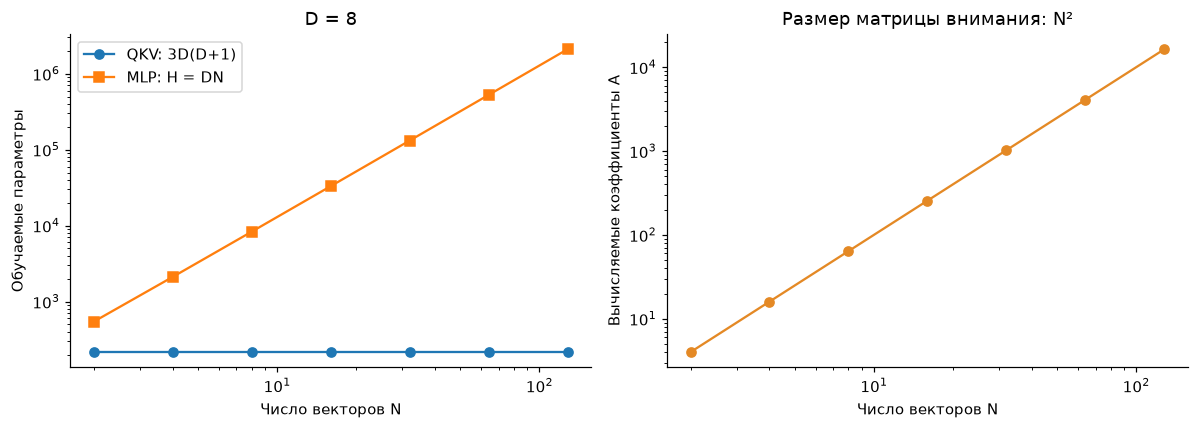

In [2]:
counts = tables['parameter_counts']
display(counts[['D', 'N', 'H', 'QKV_weights', 'QKV_biases', 'QKV_parameters',
                'attention_entries', 'attention_extra_parameters', 'MLP_parameters']])
example = parameter_counts(3, 4)
print('Пример: D = 3, N = 4, H = 12')
print('Обучаемые параметры Q, K, V:', example['QKV_parameters'])
print('Вычисляемые коэффициенты внимания:', example['attention_entries'])
print('Параметры перцептрона:', example['MLP_parameters'])

subset = counts[counts.D == 8]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].loglog(subset.N, subset.QKV_parameters, 'o-', label='QKV: 3D(D+1)')
axes[0].loglog(subset.N, subset.MLP_parameters, 's-', label='MLP: H = DN')
axes[0].set(xlabel='Число векторов N', ylabel='Обучаемые параметры', title='D = 8')
axes[0].legend()
axes[1].loglog(subset.N, subset.attention_entries, 'o-', color='#e48925')
axes[1].set(xlabel='Число векторов N', ylabel='Вычисляемые коэффициенты A', title='Размер матрицы внимания: N²')
show_figure(fig, 'parameter_counts.png')

При $D=3,N=4$ получено 36 обучаемых параметров QKV, 16 коэффициентов внимания
и 312 параметров перцептрона при $H=12$. При фиксированном $D$ число параметров
QKV не зависит от $N$, но память под матрицу внимания растёт как $N^2$.

### 2. Задача 2. Эквивариантность относительно перестановок

Пусть $P$ - матрица перестановки столбцов. Тогда
$PP^T=P^TP=I$ и $\mathbf1_N^TP=\mathbf1_N^T$.
Для любой из общих аффинных проекций:

$$Q(XP)=W_QXP+b_Q\mathbf1_N^T
=(W_QX+b_Q\mathbf1_N^T)P=Q(X)P.$$

Аналогично $K(XP)=K(X)P$ и $V(XP)=V(X)P$. Если $S=K^TQ/\sqrt D$, тогда

$$S(XP)=\frac{(KP)^T(QP)}{\sqrt D}=P^TS(X)P.$$

Нормирую softmax **по каждому столбцу**, то есть по всем ключам для одного запроса:

$$A_{ij}=\frac{e^{S_{ij}}}{\sum_{r=1}^N e^{S_{rj}}}.$$

Если $p(j)$ - исходный индекс столбца, перемещённого на позицию $j$, то

$$\left[\operatorname{softmax}_{col}(P^TSP)\right]_{ij}
=\frac{e^{S_{p(i),p(j)}}}{\sum_r e^{S_{p(r),p(j)}}}
=A_{p(i),p(j)}.$$

В знаменателе перестановка только меняет порядок слагаемых, поэтому
$A(XP)=P^TA(X)P$. Окончательно:

$$Sa(XP)=V(XP)A(XP)=VP\,P^TAP=VAP={Sa(X)P}.$$

Следовательно, самовнимание эквивариантно: вместе со входами переставляются
выходы.

In [3]:
x = tables['input'].to_numpy()
p = tables['permutation'].to_numpy()
parameters = initialize(3, seed=2026)
original = self_attention(x, parameters)
permuted = self_attention(x @ p, parameters)
print('Матрица перестановки:')
display(tables['permutation'])
print('Вход X:')
display(tables['input'])
for name, matrix in [('V', original.values), ('K', original.keys), ('Q', original.queries)]:
    print(name)
    display(pd.DataFrame(matrix))
print('Sa(XP):')
display(pd.DataFrame(permuted.output))
print('Sa(X)P:')
display(pd.DataFrame(original.output @ p))
np.testing.assert_allclose(permuted.output, original.output @ p, rtol=RTOL, atol=ATOL)
np.testing.assert_allclose(permuted.weights, p.T @ original.weights @ p, rtol=RTOL, atol=ATOL)
print('Максимальное расхождение:', f'{np.max(np.abs(permuted.output - original.output @ p)):.4e}')

Матрица перестановки:


,0,1,2,3
0,0.0000e+00,0.0000e+00,1.0000e+00,0.0000e+00
1,1.0000e+00,0.0000e+00,0.0000e+00,0.0000e+00
2,0.0000e+00,0.0000e+00,0.0000e+00,1.0000e+00
3,0.0000e+00,1.0000e+00,0.0000e+00,0.0000e+00


Вход X:


,0,1,2,3
0,2.0000e-01,1.0000e+00,-5.0000e-01,7.0000e-01
1,1.2000e+00,-3.0000e-01,8.0000e-01,1.0000e-01
2,-4.0000e-01,6.0000e-01,1.1000e+00,-2.0000e-01


V


,0,1,2,3
0,7.6436e-02,-4.2302e-01,1.9612e-01,-2.4455e-01
1,-2.2281e-01,1.8173e-01,3.6165e-01,-6.9869e-02
2,-2.8329e-01,6.7758e-01,-2.0866e-01,3.0475e-01


... (5 outputs left out)

,0,1,2,3
0,-9.8703e-02,-1.0015e-01,-9.9843e-02,-9.2976e-02
1,6.2909e-02,5.9177e-02,6.8058e-02,8.4786e-02
2,1.2262e-01,1.2324e-01,1.2671e-01,1.2332e-01


Sa(X)P:


,0,1,2,3
0,-9.8703e-02,-1.0015e-01,-9.9843e-02,-9.2976e-02
1,6.2909e-02,5.9177e-02,6.8058e-02,8.4786e-02
2,1.2262e-01,1.2324e-01,1.2671e-01,1.2332e-01


Максимальное расхождение: 4.1633e-17


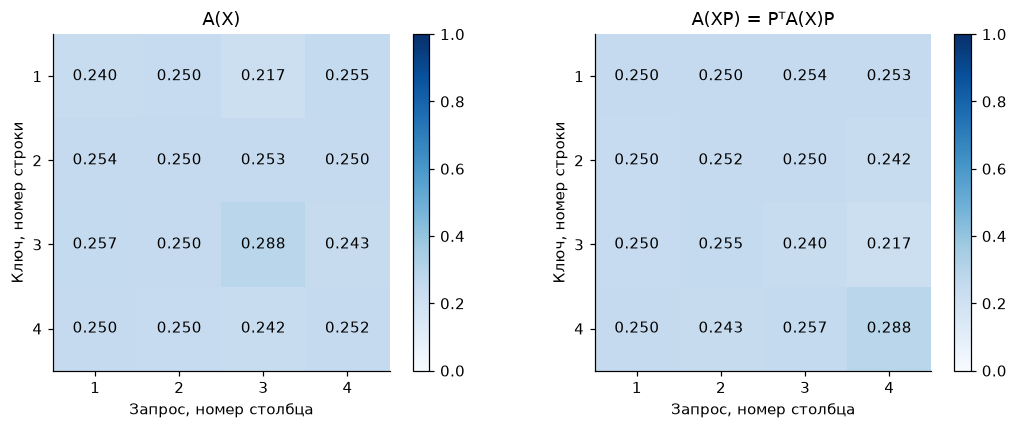

,D,N,scaled,checks,output_error,attention_error
0,2,3,False,6,5.5511e-17,0.0000e+00
1,2,3,True,6,1.1102e-16,5.5511e-17
2,3,4,False,24,4.1633e-17,2.7756e-17
3,3,4,True,24,4.1633e-17,5.5511e-17
4,8,12,False,30,4.4409e-16,1.1102e-16
5,8,12,True,30,4.4409e-16,1.1102e-16


Всего проверок перестановок: 120


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, weights, title in zip(axes, (original.weights, permuted.weights), ('A(X)', 'A(XP) = PᵀA(X)P')):
    im = ax.imshow(weights, vmin=0, vmax=1, cmap='Blues')
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f'{weights[i,j]:.3f}', ha='center', va='center')
    ax.set(xlabel='Запрос, номер столбца', ylabel='Ключ, номер строки', title=title,
           xticks=range(4), yticks=range(4), xticklabels=range(1,5), yticklabels=range(1,5))
    fig.colorbar(im, ax=ax, fraction=.046)
show_figure(fig, 'attention_permutation.png')

checks = tables['equivariance']
display(checks.groupby(['D', 'N', 'scaled'], as_index=False).agg(
    checks=('permutation_id', 'size'), output_error=('output_max_error', 'max'),
    attention_error=('attention_max_error', 'max')))
assert len(checks) == 120
assert checks.output_max_error.max() < ATOL
print('Всего проверок перестановок:', len(checks))

Для $N=3$ и $N=4$ проверены все перестановки; для $N=12$ - 30 случайных
перестановок с фиксированным seed. Каждая проверка выполнена с масштабированием
и без него.

### 3. Задача 3. Все производные softmax

Даны $z=(-3,1,100,5,-1)$ и $y_i=e^{z_i}/\sum_{k=1}^5e^{z_k}$.
По правилу дифференцирования частного:

$$\frac{\partial y_i}{\partial z_j}
=\frac{\delta_{ij}e^{z_i}\sum_k e^{z_k}-e^{z_i}e^{z_j}}
{(\sum_k e^{z_k})^2}
={y_i(\delta_{ij}-y_j)}.$$

Таким образом, диагональные элементы равны $y_i(1-y_i)$, а внедиагональные
равны $-y_iy_j$. Строка $i$ соответствует выходу $y_i$, столбец $j$ - входу $z_j$.

Для вычисления softmax вычитаю максимум $m=100$:

$$y_i=\frac{e^{z_i-m}}{\sum_k e^{z_k-m}}.$$

После сдвига показатель для третьего элемента равен нулю, остальные равны
$-103,-99,-95,-101$. Однако float64 округляет $y_3$ до единицы, поскольку $1-y_3$ имеет порядок $10^{-42}$.
Прямое вычисление $y_3(1-y_3)$ тогда ошибочно даёт ноль.

Чтобы сохранить малую диагональ, использую тождество

$$J_{ii}=y_i\sum_{k\ne i}y_k.$$

Это та же формула производной, записанная через сумму остальных вероятностей.
Численные ответы вывожу с пятью значащими цифрами.

In [5]:
print('Вероятности softmax:')
display(tables['softmax'])
print('Все 25 производных:')
jacobian = softmax_jacobian(LOGITS)
display(tables['jacobian'])
print('J33:', f'{jacobian[2,2]:.4e}')

Вероятности softmax:


,i,z,y
0,1,-3.0000e+00,1.8521e-45
1,2,1.0000e+00,1.0112e-43
2,3,1.0000e+02,1.0000e+00
3,4,5.0000e+00,5.5211e-42
4,5,-1.0000e+00,1.3685e-44


Все 25 производных:


,z1,z2,z3,z4,z5
y1,1.8521e-45,-1.8729e-88,-1.8521e-45,-1.0226e-86,-2.5347e-89
y2,-1.8729e-88,1.0112e-43,-1.0112e-43,-5.5830e-85,-1.3839e-87
y3,-1.8521e-45,-1.0112e-43,5.6377e-42,-5.5211e-42,-1.3685e-44
y4,-1.0226e-86,-5.5830e-85,-5.5211e-42,5.5211e-42,-7.5558e-86
y5,-2.5347e-89,-1.3839e-87,-1.3685e-44,-7.5558e-86,1.3685e-44


J33: 5.6377e-42


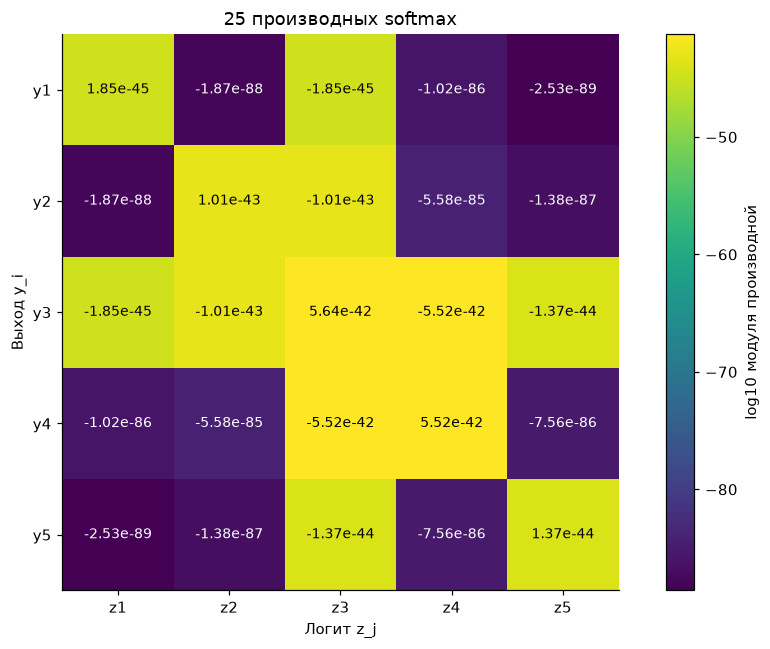

Наибольший модуль производной: 5.6377e-42


In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(np.log10(np.abs(jacobian)), cmap='viridis')
for i in range(5):
    for j in range(5):
        color = 'black' if np.log10(abs(jacobian[i,j])) > -60 else 'white'
        ax.text(j, i, f'{jacobian[i,j]:.2e}', ha='center', va='center', color=color, fontsize=9)
ax.set(xticks=range(5), yticks=range(5), xticklabels=[f'z{j}' for j in range(1,6)],
       yticklabels=[f'y{i}' for i in range(1,6)], xlabel='Логит z_j', ylabel='Выход y_i',
       title='25 производных softmax')
fig.colorbar(im, ax=ax, label='log10 модуля производной')
show_figure(fig, 'softmax_jacobian.png')

print('Наибольший модуль производной:', f'{np.max(np.abs(jacobian)):.4e}')


#### Выводы по значениям производных

Максимальный элемент по модулю - $J_{33}\approx5.6377\cdot10^{-42}$.
Все 25 производных очень малы: логит 100 существенно больше ближайшего конкурента 5,
и softmax почти полностью сосредоточена на третьем выходе.
Малые изменения отдельных логитов слабо меняют вероятности в этой точке.
Внедиагональные производные отрицательны: увеличение одного логита уменьшает
остальные вероятности. Диагональные производные положительны.

### 4. Проверки и воспроизводимость

Для численных примеров фиксирован `seed=2026`. Матрицы весов и смещений
сохранены в `results/attention_parameters.npz`. В CSV находятся подсчёты параметров,
исходные матрицы, проверки перестановок и все 25 производных.

Тесты проверяют подсчёт параметров, вычисление самовнимания и равенство
при перестановке входов. Для численных проверок использую относительный допуск
`1e-5` и абсолютный `1e-7`. Малые производные сравниваются с нулевым абсолютным
допуском, чтобы не принять нулевую матрицу за правильный ответ.

Запуск из корня проекта:

```powershell
.\.venv\Scripts\python.exe -m unittest discover -s Lab6/tests -v
.\.venv\Scripts\python.exe run_labs.py 6
```

### Итоги

1. QKV используют $3D(D+1)$ обучаемых параметров. В матрице внимания $N^2$
   вычисляемых коэффициентов. Перцептрон имеет $2DNH+H+DN$ параметров;
   при $H=DN$ получается $2(DN)^2+2DN$.
2. Доказано $Sa(XP)=Sa(X)P$. Численная проверка охватывает 120 случаев
   с масштабированием внимания и без него.
3. Найдены все 25 производных. Их значения очень малы, поскольку третий вход
   значительно больше остальных.